In [ ]:
!pip install mlflow -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 kB 2.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.5/50.5 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 91.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 81.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 56.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 74.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.2/216.2 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 123.9/123.9 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 132.

**Import Libraries**

In [ ]:
import mlflow
import mlflow.sklearn

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

**Load Titanic Dataset**

In [ ]:
import pandas as pd

df = pd.read_csv("CSE_Skill_Gap_Dataset_1000.csv")

X = df[
    [
        "CurriculumCoverage",
        "IndustryDemand",
        "JobFrequency",
        "ExpertImportance",
        "Programming",
        "DataStructures",
        "Algorithms",
        "Database",
        "WebDevelopment",
        "Cloud",
        "AI_ML",
        "Communication",
        "ProblemSolving",
        "Teamwork",
        "Projects",
        "Internship",
        "Certifications",
        "CurriculumAlignment",
        "IndustryRequirement",
        "SkillGap"
    ]
]

y = df["GapStatus"]

**Split the Dataset**

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 800
Testing records: 200


**Create the Preprocessing Pipeline**

In [ ]:
numerical_features = [
    "CurriculumCoverage",
    "IndustryDemand",
    "JobFrequency",
    "ExpertImportance",
    "Programming",
    "DataStructures",
    "Algorithms",
    "Database",
    "WebDevelopment",
    "Cloud",
    "AI_ML",
    "Communication",
    "ProblemSolving",
    "Teamwork",
    "Projects",
    "Internship",
    "Certifications",
    "CurriculumAlignment",
    "IndustryRequirement",
    "SkillGap"
]

categorical_features = []

In [ ]:
numerical_pipeline = Pipeline(
    steps=[
        ("missing_values", SimpleImputer(strategy="median")),
        ("scaling", StandardScaler())
    ]
)

In [ ]:
categorical_pipeline = Pipeline(
    steps=[
        ("missing_values", SimpleImputer(strategy="most_frequent")),
        ("encoding", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)

**Create an MLflow Experiment**

In [ ]:
mlflow.set_experiment(
    "Curriculum Industry Skill Gap Prediction"
)

2026/08/24 05:53:08 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/08/24 05:53:08 INFO mlflow.store.db.utils: Updating database tables
2026/08/24 05:53:11 INFO mlflow.tracking.fluent: Experiment with name 'Curriculum Industry Skill Gap Prediction' does not exist. Creating a new experiment.


<Experiment: artifact_location='/content/mlruns/1', creation_time=1787550791332, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1787550791332, lifecycle_stage='active', name='Curriculum Industry Skill Gap Prediction', tags={}, trace_location=None, workspace='default'>

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

import mlflow
import mlflow.sklearn

**Run the First Experiment**

In [ ]:
with mlflow.start_run(run_name="Logistic Regression"):

    model_pipeline = Pipeline(
        steps=[
            ("preprocessing", preprocessor),
            (
                "model",
                LogisticRegression(
                    C=1.0,
                    max_iter=1000
                )
            )
        ]
    )

    model_pipeline.fit(X_train, y_train)

    predictions = model_pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    mlflow.log_param("model", "LogisticRegression")
    mlflow.log_param("C", 1.0)

    mlflow.log_metric("accuracy", accuracy)

    mlflow.sklearn.log_model(
        sk_model=model_pipeline,
        name="model",
        serialization_format="cloudpickle"
    )

    print("Logistic Regression Accuracy:", accuracy)

2026/08/24 05:54:06 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logistic Regression Accuracy: 0.985


**Run a Second Experiment**

In [ ]:
with mlflow.start_run(run_name="Decision Tree"):

    model_pipeline = Pipeline(
        steps=[
            ("preprocessing", preprocessor),
            (
                "model",
                DecisionTreeClassifier(
                    max_depth=5,
                    random_state=42
                )
            )
        ]
    )

    model_pipeline.fit(X_train, y_train)

    predictions = model_pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    mlflow.log_param("model", "DecisionTree")
    mlflow.log_param("max_depth", 5)

    mlflow.log_metric("accuracy", accuracy)

    mlflow.sklearn.log_model(
        sk_model=model_pipeline,
        name="model",
        serialization_format="cloudpickle"
    )

    print("Decision Tree Accuracy:", accuracy)

2026/08/24 05:54:39 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Decision Tree Accuracy: 1.0


**Run a Third Experiment**

In [ ]:
with mlflow.start_run(run_name="Random Forest"):

    model_pipeline = Pipeline(
        steps=[
            ("preprocessing", preprocessor),
            (
                "model",
                RandomForestClassifier(
                    n_estimators=100,
                    max_depth=5,
                    random_state=42
                )
            )
        ]
    )

    model_pipeline.fit(X_train, y_train)

    predictions = model_pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    mlflow.log_param("model", "RandomForest")
    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("max_depth", 5)

    mlflow.log_metric("accuracy", accuracy)

    mlflow.sklearn.log_model(
        sk_model=model_pipeline,
        name="model",
        serialization_format="cloudpickle"
    )

    print("Random Forest Accuracy:", accuracy)

2026/08/24 05:55:20 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Random Forest Accuracy: 1.0


**Log All Important Parameters**

In [ ]:
models = {
    "LogisticRegression": LogisticRegression(
        C=1.0,
        max_iter=1000
    ),

    "DecisionTree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "RandomForest": RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42
    )
}

In [ ]:
for model_name, model in models.items():

    with mlflow.start_run(run_name=model_name):

        pipeline = Pipeline(
            steps=[
                ("preprocessing", preprocessor),
                ("model", model)
            ]
        )

        pipeline.fit(X_train, y_train)

        predictions = pipeline.predict(X_test)

        accuracy = accuracy_score(
            y_test,
            predictions
        )

        mlflow.log_param(
            "model",
            model_name
        )

        mlflow.log_metric(
            "accuracy",
            accuracy
        )

        mlflow.sklearn.log_model(
            sk_model=pipeline,
            name="model",
            serialization_format="cloudpickle"
        )

        print(
            model_name,
            "Accuracy:",
            accuracy
        )

2026/08/24 05:55:53 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/08/24 05:55:58 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


LogisticRegression Accuracy: 0.985
DecisionTree Accuracy: 1.0


2026/08/24 05:56:03 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


RandomForest Accuracy: 1.0


**ML FLOW UI**

In [ ]:
import mlflow

mlflow.set_tracking_uri("sqlite:////content/mlflow.db")

mlflow.set_experiment(
    "CSE Skill Gap Prediction"
)

print("Tracking URI:", mlflow.get_tracking_uri())

2026/08/24 05:57:21 INFO mlflow.tracking.fluent: Experiment with name 'CSE Skill Gap Prediction' does not exist. Creating a new experiment.


Tracking URI: sqlite:////content/mlflow.db


In [ ]:
experiment = mlflow.get_experiment_by_name(
    "Curriculum Industry Skill Gap Prediction"
)

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id]
)

comparison = runs[
    [
        "tags.mlflow.runName",
        "params.model",
        "metrics.accuracy"
    ]
].sort_values(
    "metrics.accuracy",
    ascending=False
)

comparison

,tags.mlflow.runName,params.model,metrics.accuracy
0,RandomForest,RandomForest,1.000
1,DecisionTree,DecisionTree,1.000
3,Random Forest,RandomForest,1.000
4,Decision Tree,DecisionTree,1.000
2,LogisticRegression,LogisticRegression,0.985
5,Logistic Regression,LogisticRegression,0.985


**Get all Parameters**

In [ ]:
for model_name, model in models.items():

    with mlflow.start_run(run_name=model_name):

        pipeline = Pipeline(
            steps=[
                ("preprocessing", preprocessor),
                ("model", model)
            ]
        )

        pipeline.fit(X_train, y_train)

        predictions = pipeline.predict(X_test)

        accuracy = accuracy_score(y_test, predictions)

        mlflow.log_param("model", model_name)

        mlflow.log_params(model.get_params())

        mlflow.log_metric("accuracy", accuracy)

        mlflow.sklearn.log_model(
            sk_model=pipeline,
            name="model",
            serialization_format="cloudpickle"
        )

        print(model_name, "Accuracy:", accuracy)

2026/08/24 06:03:27 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/08/24 06:03:32 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


LogisticRegression Accuracy: 0.985
DecisionTree Accuracy: 1.0


2026/08/24 06:03:40 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


RandomForest Accuracy: 1.0


In [ ]:
experiment = mlflow.get_experiment_by_name(
    "CSE Skill Gap Prediction"
)

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id]
)

runs

,run_id,experiment_id,status,artifact_uri,start_time,end_time,metrics.accuracy,params.min_samples_leaf,params.model,params.bootstrap,...,params.max_iter,params.multi_class,params.fit_intercept,params.C,params.dual,params.l1_ratio,tags.mlflow.source.name,tags.mlflow.runName,tags.mlflow.source.type,tags.mlflow.user
0,109a0a5886174bbcbbc154e5b6686b5b,2,FINISHED,/content/mlruns/2/109a0a5886174bbcbbc154e5b668...,2026-08-24 06:03:39.254000+00:00,2026-08-24 06:03:51.562000+00:00,1.000,1,RandomForest,True,...,None,None,None,None,None,None,fileId=1wq30iaFl4Syqnw8Igad6LhSlHf9E_lrc,RandomForest,NOTEBOOK,root
1,787dc2d795c4461bb6e73fb050c4af43,2,FINISHED,/content/mlruns/2/787dc2d795c4461bb6e73fb050c4...,2026-08-24 06:03:32.359000+00:00,2026-08-24 06:03:39.221000+00:00,1.000,1,DecisionTree,None,...,None,None,None,None,None,None,fileId=1wq30iaFl4Syqnw8Igad6LhSlHf9E_lrc,DecisionTree,NOTEBOOK,root
2,31dacd72c8124ea682aa625212184e55,2,FINISHED,/content/mlruns/2/31dacd72c8124ea682aa62521218...,2026-08-24 06:03:27.495000+00:00,2026-08-24 06:03:32.345000+00:00,0.985,None,LogisticRegression,None,...,1000,deprecated,True,1.0,False,None,fileId=1wq30iaFl4Syqnw8Igad6LhSlHf9E_lrc,LogisticRegression,NOTEBOOK,root
3,b6be9765c3eb4cec9cc0563d680717d1,2,FINISHED,/content/mlruns/2/b6be9765c3eb4cec9cc0563d6807...,2026-08-24 06:03:07.626000+00:00,2026-08-24 06:03:21.411000+00:00,1.000,1,RandomForest,True,...,None,None,None,None,None,None,fileId=1wq30iaFl4Syqnw8Igad6LhSlHf9E_lrc,RandomForest,NOTEBOOK,root
4,1c4c62b086494554a54ccdca1a0340a9,2,FINISHED,/content/mlruns/2/1c4c62b086494554a54ccdca1a03...,2026-08-24 06:03:01.843000+00:00,2026-08-24 06:03:07.610000+00:00,1.000,1,DecisionTree,None,...,None,None,None,None,None,None,fileId=1wq30iaFl4Syqnw8Igad6LhSlHf9E_lrc,DecisionTree,NOTEBOOK,root
5,8034bb7c0221404dbb653b1bdb21b13a,2,FINISHED,/content/mlruns/2/8034bb7c0221404dbb653b1bdb21...,2026-08-24 06:02:55.373000+00:00,2026-08-24 06:03:01.825000+00:00,0.985,None,LogisticRegression,None,...,1000,deprecated,True,1.0,False,None,fileId=1wq30iaFl4Syqnw8Igad6LhSlHf9E_lrc,LogisticRegression,NOTEBOOK,root


In [ ]:
comparison = runs[
    [
        "tags.mlflow.runName",
        "params.model",
        "params.C",
        "params.max_depth",
        "params.n_estimators",
        "metrics.accuracy"
    ]
].sort_values(
    "metrics.accuracy",
    ascending=False
)

comparison

,tags.mlflow.runName,params.model,params.C,params.max_depth,params.n_estimators,metrics.accuracy
0,RandomForest,RandomForest,None,5,100,1.000
1,DecisionTree,DecisionTree,None,5,None,1.000
3,RandomForest,RandomForest,None,5,100,1.000
4,DecisionTree,DecisionTree,None,5,None,1.000
2,LogisticRegression,LogisticRegression,1.0,None,None,0.985
5,LogisticRegression,LogisticRegression,1.0,None,None,0.985


**Best Model**

In [26]:
import pandas as pd

comparison = runs[
    [
        "tags.mlflow.runName",
        "params.model",
        "params.C",
        "params.max_depth",
        "params.n_estimators",
        "metrics.accuracy"
    ]
].copy()

comparison.columns = [
    "Run Name",
    "Model",
    "C",
    "Max Depth",
    "No. of Trees",
    "Accuracy"
]

comparison = comparison.dropna(
    subset=["Model", "Accuracy"]
)

comparison["Accuracy"] = (
    comparison["Accuracy"] * 100
).round(2)

comparison = comparison.sort_values(
    "Accuracy",
    ascending=False
)

comparison

,Run Name,Model,C,Max Depth,No. of Trees,Accuracy
0,RandomForest,RandomForest,None,5,100,100.0
1,DecisionTree,DecisionTree,None,5,None,100.0
3,RandomForest,RandomForest,None,5,100,100.0
4,DecisionTree,DecisionTree,None,5,None,100.0
2,LogisticRegression,LogisticRegression,1.0,None,None,98.5
5,LogisticRegression,LogisticRegression,1.0,None,None,98.5


In [27]:
best_models = (
    comparison
    .sort_values("Accuracy", ascending=False)
    .drop_duplicates(subset=["Model"])
    .reset_index(drop=True)
)

best_models

,Run Name,Model,C,Max Depth,No. of Trees,Accuracy
0,RandomForest,RandomForest,None,5,100,100.0
1,DecisionTree,DecisionTree,None,5,None,100.0
2,LogisticRegression,LogisticRegression,1.0,None,None,98.5


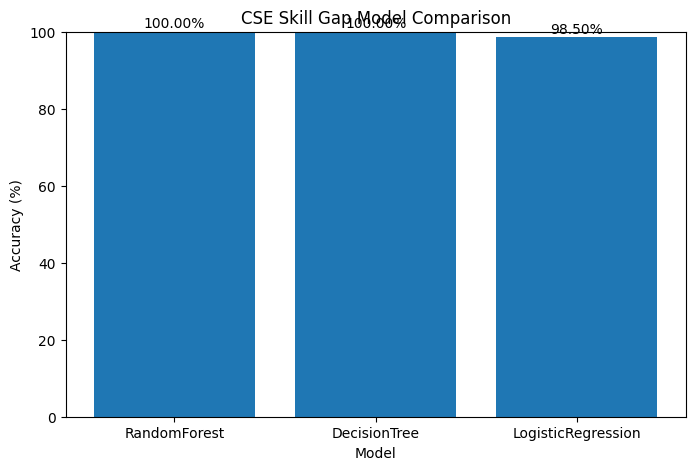

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    best_models["Model"],
    best_models["Accuracy"]
)

plt.xlabel("Model")
plt.ylabel("Accuracy (%)")

plt.title("CSE Skill Gap Model Comparison")

plt.ylim(0, 100)

for i, value in enumerate(best_models["Accuracy"]):
    plt.text(
        i,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.show()

In [29]:
display(
    best_models[
        [
            "Model",
            "C",
            "Max Depth",
            "No. of Trees",
            "Accuracy"
        ]
    ].style
    .format({"Accuracy": "{:.2f}%"})
    .highlight_max(
        subset=["Accuracy"],
        axis=0
    )
)

,Model,C,Max Depth,No. of Trees,Accuracy
0,RandomForest,None,5,100,100.00%
1,DecisionTree,None,5,None,100.00%
2,LogisticRegression,1.0,None,None,98.50%
